In [3]:
import pandas as pd
df=pd.read_csv("Zomato.csv")
df

,Restaurant_Name,Dining_Rating,Delivery_Rating,Dining Votes,Delivery_Votes,Cuisine,Place_Name,City,Item_Name,Best_Seller,Votes,Prices
0,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Platter Kebab Combo,BESTSELLER,84,249.0
1,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Chicken Rumali Shawarma,BESTSELLER,45,129.0
2,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Chicken Tandoori Salad,NaN,39,189.0
3,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Chicken BBQ Salad,BESTSELLER,43,189.0
4,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Special Doner Wrap Combo,MUST TRY,31,205.0
...,...,...,...,...,...,...,...,...,...,...,...,...
123652,Ariena Boutique Hotel,3.9,4.2,13,523,Pizza,Purena,Raipur,Murgh Reshmi Kebab,NaN,0,525.0
123653,Ariena Boutique Hotel,3.9,4.2,13,523,Pizza,Purena,Raipur,Murgh Large Tikka,NaN,0,525.0
123654,Ariena Boutique Hotel,3.9,4.2,13,523,Pizza,Purena,Raipur,Murgh Chukandri Tikka,NaN,0,525.0
123655,Ariena Boutique Hotel,3.9,4.2,13,523,Pizza,Purena,Raipur,Murgh Golden Kebab,NaN,0,525.0


In [4]:
df.isnull()

,Restaurant_Name,Dining_Rating,Delivery_Rating,Dining Votes,Delivery_Votes,Cuisine,Place_Name,City,Item_Name,Best_Seller,Votes,Prices
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
123652,False,False,False,False,False,False,False,False,False,True,False,False
123653,False,False,False,False,False,False,False,False,False,True,False,False
123654,False,False,False,False,False,False,False,False,False,True,False,False
123655,False,False,False,False,False,False,False,False,False,True,False,False


In [5]:
df.isnull().sum()

Restaurant_Name        0
Dining_Rating      32236
Delivery_Rating     1280
Dining Votes           0
Delivery_Votes         0
Cuisine                0
Place_Name             0
City                   0
Item_Name              0
Best_Seller        95715
Votes                  0
Prices                 0
dtype: int64

In [6]:
dff=pd.DataFrame(df)
dff.dtypes

Restaurant_Name     object
Dining_Rating      float64
Delivery_Rating    float64
Dining Votes         int64
Delivery_Votes       int64
Cuisine             object
Place_Name          object
City                object
Item_Name           object
Best_Seller         object
Votes                int64
Prices             float64
dtype: object

In [14]:
df['Dining_Rating'].fillna('Unknown', inplace=True)
df['Delivery_Rating'].fillna('Unknown', inplace=True)
df['Best_Seller'].fillna('Unknown', inplace=True)

df.isnull().sum()

Restaurant_Name    0
Dining_Rating      0
Delivery_Rating    0
Dining Votes       0
Delivery_Votes     0
Cuisine            0
Place_Name         0
City               0
Item_Name          0
Best_Seller        0
Votes              0
Prices             0
dtype: int64

In [13]:
df['Prices']=df['Prices'].astype(int)
df['Votes']=df['Votes'].astype(float)
df.dtypes


Restaurant_Name     object
Dining_Rating      float64
Delivery_Rating    float64
Dining Votes         int64
Delivery_Votes       int64
Cuisine             object
Place_Name          object
City                object
Item_Name           object
Best_Seller         object
Votes              float64
Prices               int64
dtype: object

In [17]:
df = df[['Dining_Rating', 'Delivery_Rating', 'Dining Votes',  'City']]

# Check result
print(df.head())

  Dining_Rating Delivery_Rating  Dining Votes        City
0           3.9             4.2            39   Hyderabad
1           3.9             4.2            39   Hyderabad
2           3.9             4.2            39   Hyderabad
3           3.9             4.2            39   Hyderabad
4           3.9             4.2            39   Hyderabad


In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("Zomato.csv")

# Check missing values
print(df.isnull().sum())

# Convert ratings to numeric
df['Dining_Rating'] = pd.to_numeric(df['Dining_Rating'], errors='coerce')
df['Delivery_Rating'] = pd.to_numeric(df['Delivery_Rating'], errors='coerce')

# Fill missing values with mean
df['Dining_Rating'] = df['Dining_Rating'].fillna(df['Dining_Rating'].mean())
df['Delivery_Rating'] = df['Delivery_Rating'].fillna(df['Delivery_Rating'].mean())

# Convert other columns
df['Prices'] = df['Prices'].astype(int)
df['Votes'] = df['Votes'].astype(float)

# Remove duplicates
df = df.drop_duplicates()

# Select important columns
df = df[['Dining_Rating', 'Delivery_Rating', 'Dining Votes', 'City']]

# Summary statistics
print(df.describe())



Restaurant_Name        0
Dining_Rating      32236
Delivery_Rating     1280
Dining Votes           0
Delivery_Votes         0
Cuisine                0
Place_Name             0
City                   0
Item_Name              0
Best_Seller        95715
Votes                  0
Prices                 0
dtype: int64
       Dining_Rating  Delivery_Rating   Dining Votes
count  101530.000000    101530.000000  101530.000000
mean        3.821385         3.959565     151.559726
std         0.350058         0.244990     230.662157
min         2.500000         2.500000       0.000000
25%         3.700000         3.800000       0.000000
50%         3.822264         4.000000      30.000000
75%         4.000000         4.100000     221.000000
max         4.800000         4.600000     997.000000


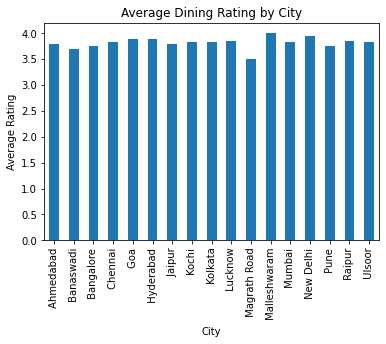

In [23]:
# Visualization
df.groupby('City')['Dining_Rating'].mean().plot(kind='bar')

plt.title("Average Dining Rating by City")
plt.xlabel("City")
plt.ylabel("Average Rating")

plt.show()

In [ ]:
#Bar Chart – Average Dining Rating by City
🔍 Interpretation:
The graph shows average dining ratings across different cities
Most cities have ratings between 3.7 to 4.2, indicating generally good restaurant quality
Some cities have slightly higher ratings, which means:
Better restaurant services
Higher customer satisfaction
There is no extreme variation, so ratings are fairly consistent across cities
📈 Insight:

👉 Restaurants across cities maintain similar quality levels, with only slight differences

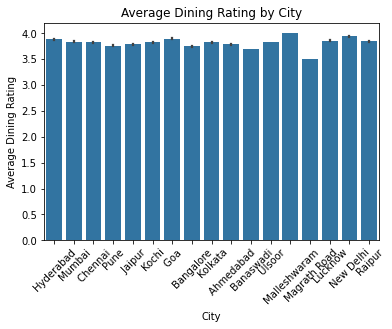

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create bar plot
sns.barplot(x='City', y='Dining_Rating', data=df)

# Add labels
plt.title("Average Dining Rating by City")
plt.xlabel("City")
plt.ylabel("Average Dining Rating")

# Rotate city names (important if many cities)
plt.xticks(rotation=45)

plt.show()

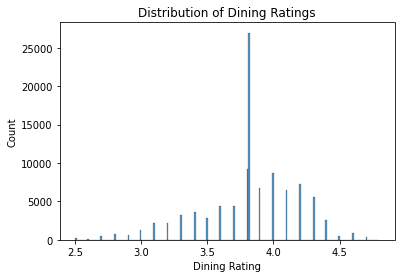

In [25]:
sns.histplot(df['Dining_Rating'])

plt.title("Distribution of Dining Ratings")
plt.xlabel("Dining Rating")
plt.ylabel("Count")

plt.show()

In [ ]:
#Interpretation:
Most ratings are concentrated between 3.5 and 4.2
Very few restaurants have:
Low ratings (< 3.0)
Very high ratings (> 4.5)
The graph shows a normal distribution (bell-shaped)
📈 Insight:

👉 Majority of restaurants provide average to good service, and very few are extremely poor or excellent

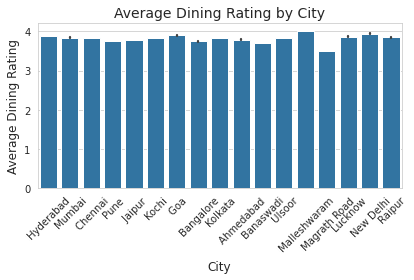

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set style (theme)
sns.set_style("whitegrid")

# Create bar plot
sns.barplot(x='City', y='Dining_Rating', data=df)

# Add title and labels
plt.title("Average Dining Rating by City", fontsize=14)
plt.xlabel("City", fontsize=12)
plt.ylabel("Average Dining Rating", fontsize=12)

# Rotate x-axis labels for readability
plt.xticks(rotation=45)

# Adjust layout
plt.tight_layout()

plt.show()